# Exploratory Data Analysis (EDA) & Data Cleaning

**Objective:** Inspect dataset structure, profile missing values, treat outliers, visualize feature relationships, and export a clean dataset ready for downstream modeling.

## 1. Setup & Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("../data/raw_dataset.csv")
print(f"Dataset loaded successfully! Shape: {df.shape}")
df.head()

Dataset loaded successfully! Shape: (584, 12)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,worst_area,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,2019.0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,1956.0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,1709.0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,567.7,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,1575.0,Malignant


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

raw_path = "../data/raw_dataset.csv"

# Auto-generate raw_dataset.csv if running standalone in Google Colab
if not os.path.exists(raw_path):
    os.makedirs("../data", exist_ok=True)
    raw_data = load_breast_cancer(as_frame=True).frame
    cols = [
        "mean radius", "mean texture", "mean perimeter", "mean area",
        "mean smoothness", "mean compactness", "mean concavity",
        "mean concave points", "mean symmetry", "mean fractal dimension",
        "worst area", "target"
    ]
    df_raw = raw_data[cols].copy()
    df_raw.columns = [c.replace(" ", "_") for c in df_raw.columns]
    df_raw["diagnosis"] = df_raw["target"].map({0: "Malignant", 1: "Benign"})
    df_raw.drop(columns=["target"], inplace=True)

    rng = np.random.default_rng(42)
    df_raw.loc[rng.choice(df_raw.index, size=38, replace=False), "mean_area"] = np.nan
    df_raw.loc[rng.choice(df_raw.index, size=24, replace=False), "mean_texture"] = np.nan
    df_raw.loc[rng.choice(df_raw.index, size=12, replace=False), "diagnosis"] = np.nan
    df_raw = pd.concat([df_raw, df_raw.iloc[:15]], ignore_index=True)
    df_raw.to_csv(raw_path, index=False)

df = pd.read_csv(raw_path)
print(f"Dataset loaded successfully! Shape: {df.shape}")
df.head()

Dataset loaded successfully! Shape: (584, 12)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,worst_area,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,2019.0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,1956.0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,1709.0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,567.7,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,1575.0,Malignant


## 2. Data Profiling & Structure Inspection

In [5]:
print("--- DATASET INFO ---")
df.info()

print("\n--- SUMMARY STATISTICS ---")
display(df.describe(include="all").round(3))

duplicate_count = df.duplicated().sum()
print(f"\nNumber of exact duplicate rows: {duplicate_count}")

--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584 entries, 0 to 583
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   mean_radius             584 non-null    float64
 1   mean_texture            560 non-null    float64
 2   mean_perimeter          584 non-null    float64
 3   mean_area               546 non-null    float64
 4   mean_smoothness         584 non-null    float64
 5   mean_compactness        584 non-null    float64
 6   mean_concavity          584 non-null    float64
 7   mean_concave_points     584 non-null    float64
 8   mean_symmetry           584 non-null    float64
 9   mean_fractal_dimension  584 non-null    float64
 10  worst_area              584 non-null    float64
 11  diagnosis               572 non-null    object 
dtypes: float64(11), object(1)
memory usage: 54.9+ KB

--- SUMMARY STATISTICS ---


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,worst_area,diagnosis
count,584.000,560.000,584.000,546.000,584.000,584.000,584.000,584.000,584.000,584.000,584.000,572
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Benign
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,350
mean,14.176,19.244,92.343,662.425,0.097,0.106,0.091,0.050,0.182,0.063,888.577,NaN
std,3.525,4.251,24.305,345.290,0.014,0.054,0.080,0.039,0.028,0.007,569.204,NaN
min,6.981,9.710,43.790,170.400,0.053,0.019,0.000,0.000,0.106,0.050,185.200,NaN
25%,11.710,16.170,75.412,428.225,0.086,0.066,0.030,0.021,0.162,0.058,516.475,NaN
50%,13.415,18.880,86.890,558.650,0.096,0.095,0.065,0.035,0.180,0.062,696.050,NaN
75%,16.022,21.705,104.800,799.700,0.106,0.131,0.134,0.075,0.197,0.066,1121.750,NaN



Number of exact duplicate rows: 15


## 3. Practice 1: Missing Value Analysis & Treatment
- **Duplicates:** Remove 15 exact duplicate records.
- **Imputation:** Fill `mean_area` with **median** (skew-resistant), `mean_texture` with **mean**, and categorical `diagnosis` with **mode**.

In [6]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_pct.round(2)
}).sort_values(by="Missing Percentage (%)", ascending=False)

print("--- MISSING VALUES SUMMARY ---")
display(missing_df[missing_df["Missing Count"] > 0])

df_clean = df.copy()
df_clean.drop_duplicates(inplace=True)

df_clean["mean_area"] = df_clean["mean_area"].fillna(df_clean["mean_area"].median())
df_clean["mean_texture"] = df_clean["mean_texture"].fillna(df_clean["mean_texture"].mean())
df_clean["diagnosis"] = df_clean["diagnosis"].fillna(df_clean["diagnosis"].mode()[0])
df_clean["diagnosis"] = df_clean["diagnosis"].astype("category")

print("\nRemaining missing values:", df_clean.isnull().sum().sum())
print(f"Cleaned dataset shape: {df_clean.shape}")

--- MISSING VALUES SUMMARY ---


,Missing Count,Missing Percentage (%)
mean_area,38,6.51
mean_texture,24,4.11
diagnosis,12,2.05



Remaining missing values: 0
Cleaned dataset shape: (569, 12)


## 4. Practice 2: Outlier Detection & Treatment (IQR Method)
Box plots highlight right-skewed outliers in `mean_area` and `worst_area`. We apply Interquartile Range (IQR) capping (`1.5 * IQR`) to normalize extreme values without losing observations.

mean_area: Found 41 outliers (Bounds: -56.15 to 1247.45)
worst_area: Found 35 outliers (Bounds: -337.75 to 1937.05)


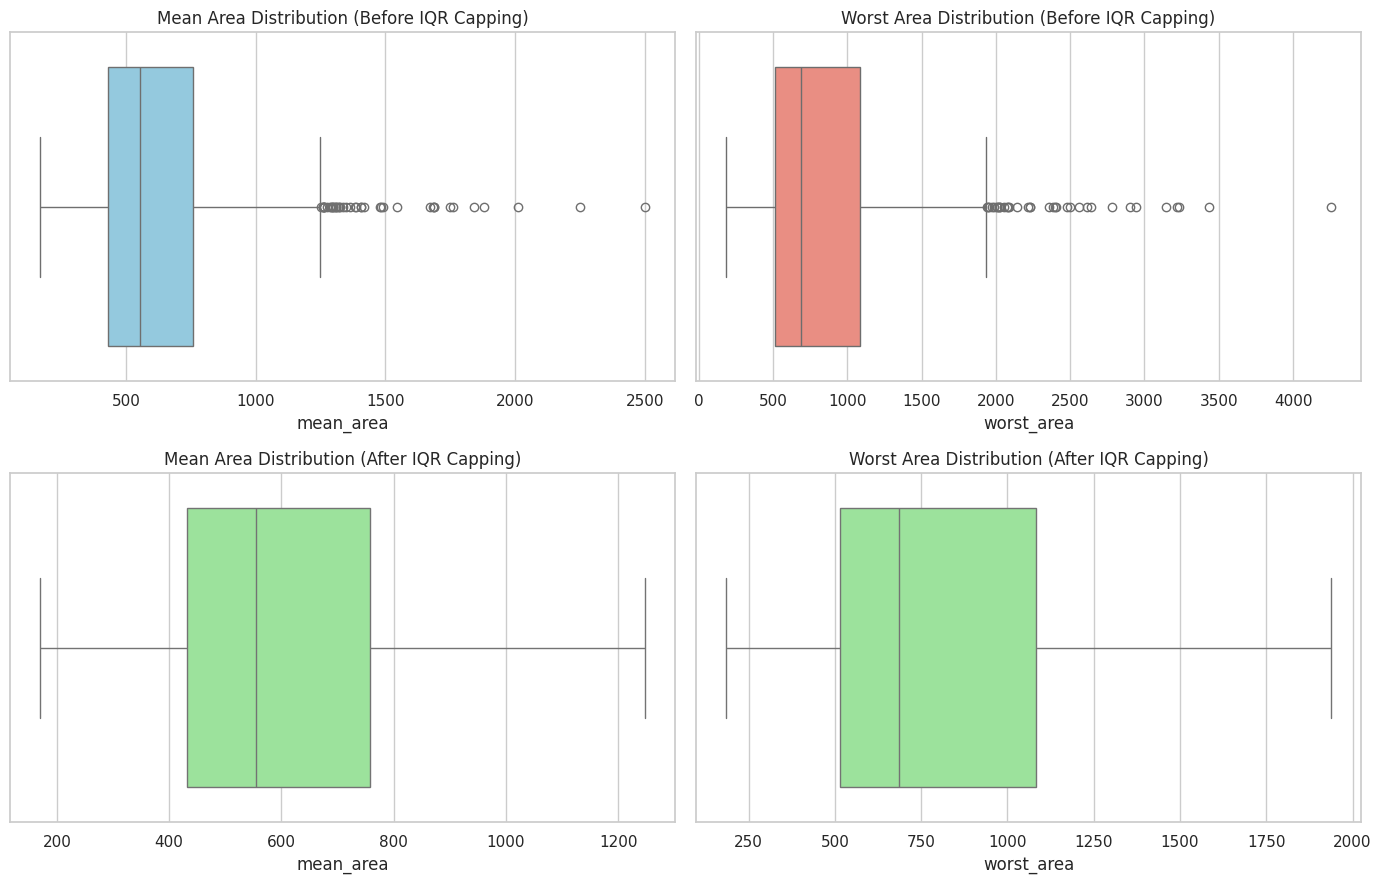

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.boxplot(x=df_clean["mean_area"], ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Mean Area Distribution (Before IQR Capping)")

sns.boxplot(x=df_clean["worst_area"], ax=axes[0, 1], color="salmon")
axes[0, 1].set_title("Worst Area Distribution (Before IQR Capping)")

def cap_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    print(f"{column}: Found {len(outliers)} outliers (Bounds: {lower_bound:.2f} to {upper_bound:.2f})")
    data[column] = np.clip(data[column], lower_bound, upper_bound)
    return data

df_clean = cap_outliers_iqr(df_clean, "mean_area")
df_clean = cap_outliers_iqr(df_clean, "worst_area")

sns.boxplot(x=df_clean["mean_area"], ax=axes[1, 0], color="lightgreen")
axes[1, 0].set_title("Mean Area Distribution (After IQR Capping)")

sns.boxplot(x=df_clean["worst_area"], ax=axes[1, 1], color="lightgreen")
axes[1, 1].set_title("Worst Area Distribution (After IQR Capping)")

plt.tight_layout()
plt.show()

## 5. Exploratory Data Analysis (Visualizations)

/tmp/ipykernel_890/2433834766.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="diagnosis", ax=axes[0, 0], palette="Set2")
/tmp/ipykernel_890/2433834766.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="diagnosis", y="mean_concavity", ax=axes[1, 0], palette="Set2")


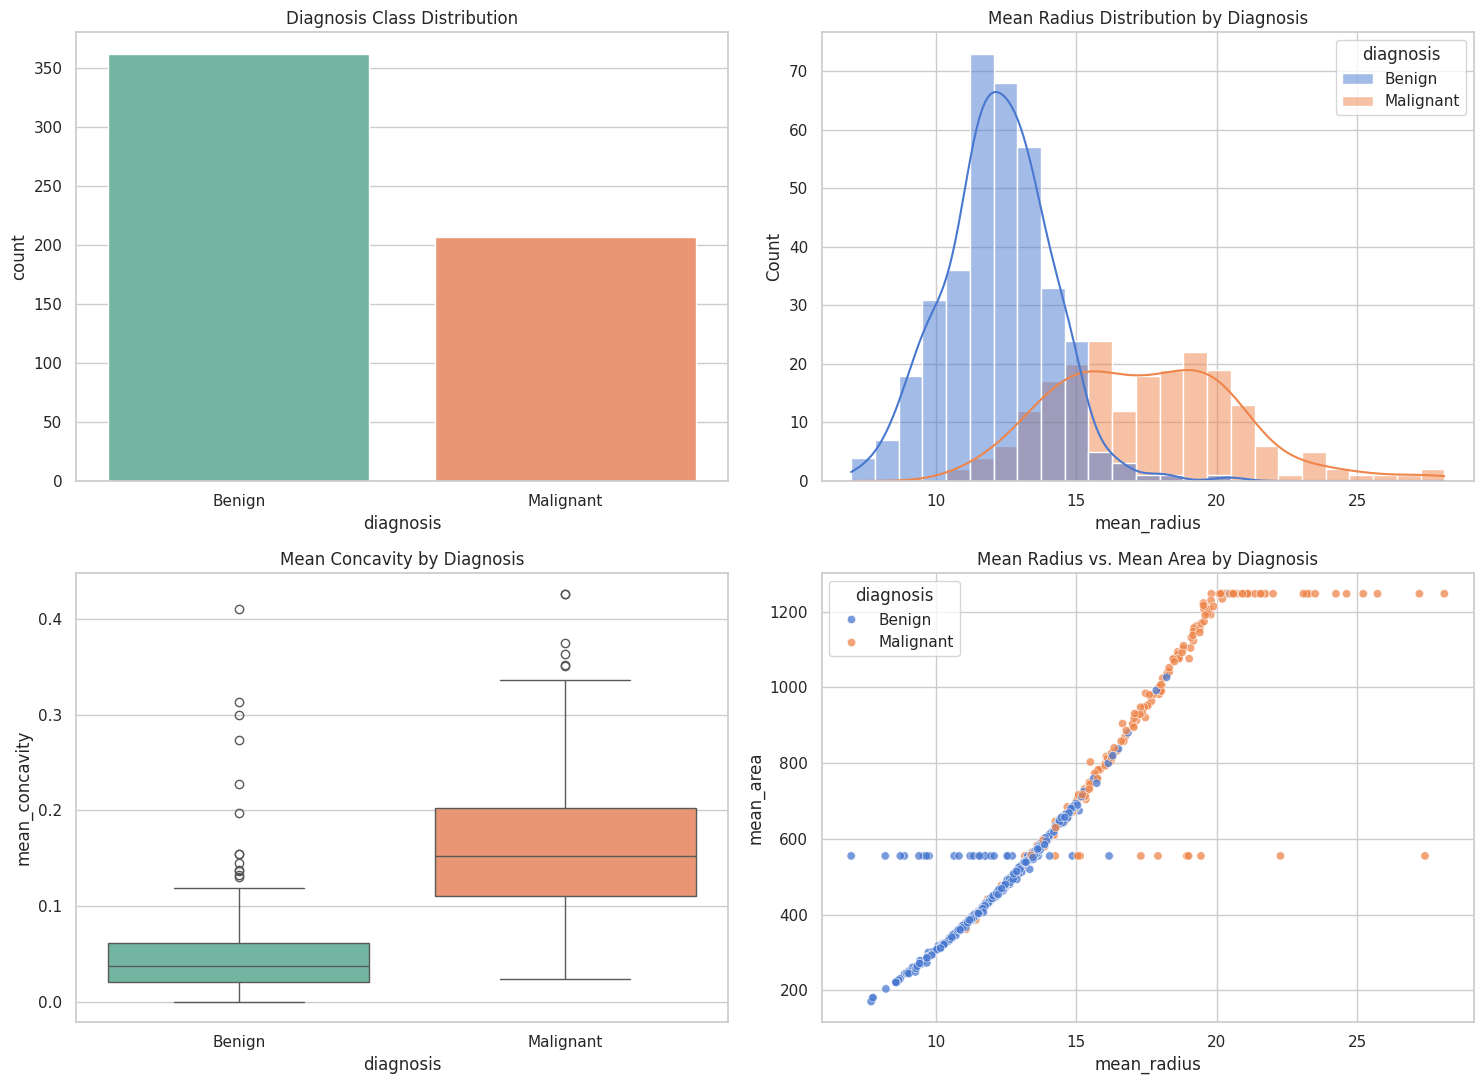

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.countplot(data=df_clean, x="diagnosis", ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Diagnosis Class Distribution")

sns.histplot(data=df_clean, x="mean_radius", hue="diagnosis", kde=True, bins=25, ax=axes[0, 1])
axes[0, 1].set_title("Mean Radius Distribution by Diagnosis")

sns.boxplot(data=df_clean, x="diagnosis", y="mean_concavity", ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Mean Concavity by Diagnosis")

sns.scatterplot(data=df_clean, x="mean_radius", y="mean_area", hue="diagnosis", alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title("Mean Radius vs. Mean Area by Diagnosis")

plt.tight_layout()
plt.show()

## 6. Practice 3: Correlation Analysis & Exporting Cleaned Data

### Top 3 Correlation Observations:
1. **Geometric Size Collinearity (`mean_radius` & `mean_perimeter`, `r = 1.00`; `mean_area`, `r = 0.98`):** Radius, perimeter, and area exhibit near-perfect positive linear correlation due to geometric scaling.
2. **Shape Irregularity (`mean_concavity` & `mean_concave_points`, `r = 0.92`):** Higher concavity strongly correlates with the number of concave contour points, providing clear separation between Benign and Malignant classes.
3. **Size vs. Fractal Dimension (`mean_area` & `mean_fractal_dimension`, `r = -0.35`):** Larger tumor areas tend to have lower fractal dimension values, showing an inverse relationship between overall size and boundary complexity.

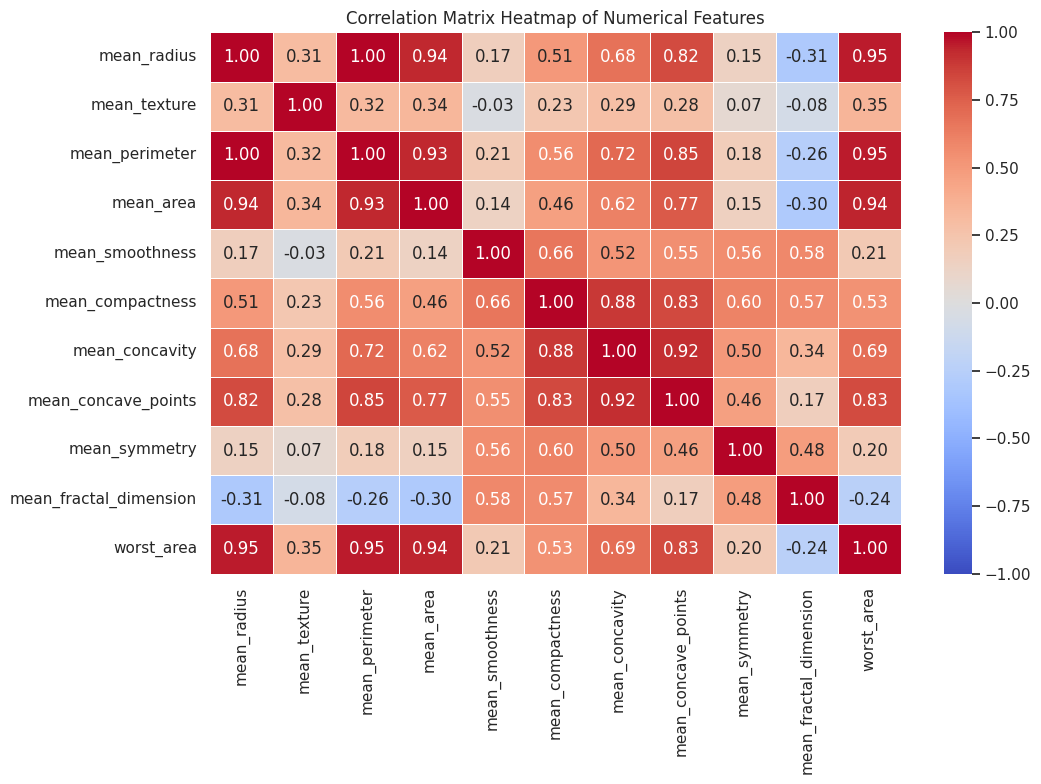

Exported cleaned dataset to ../data/cleaned_dataset.csv successfully!


In [9]:
numeric_df = df_clean.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

df_clean.to_csv("../data/cleaned_dataset.csv", index=False)
print("Exported cleaned dataset to ../data/cleaned_dataset.csv successfully!")